# Lab 3-01：embedding——把文字變成可以量距離的向量

**目標**：用 bge-m3 把一句話變成 1024 維的向量，自己算 cosine 相似度，再把海風科技的內部文件畫成散點圖、分群。

**你會學到**
- embedding 就是「文字 → 固定長度的向量」，意思相近的文字向量也相近
- cosine 相似度怎麼算，為什麼先正規化就只剩內積
- 降維看圖、KMeans 分群：向量空間真的有結構
- 相似不等於相關：向量檢索的第一個盲區

**前置**：Ollama 已有 `bge-m3`（`ollama pull bge-m3`）。原理見 `00_concepts.md` 第 1 節。

**對應投影片**：「RAG 是什麼」「向量空間與 metadata 過濾」「選型：Embedding 與重排」

![embedding 空間與最近鄰](images/embedding_space.jpg)

*圖：左邊每句話被 embedding 模型變成一排數字（向量）；右邊把向量畫成平面上的點，主題相同的文件聚成一群。朱紅星號是問題，虛線圈起來的最近幾個點就是檢索結果。*

## Step 1：一句話變成一個向量

你在深度學習課學過 CNN 的倒數第二層：一張圖進去，出來一個特徵向量。embedding 模型做的是同一件事，只是輸入換成文字。
我們用的 `bge-m3` 是多語言模型，中英文都能放進同一個向量空間。

In [1]:
import numpy as np

from course_utils.llm import embed
from course_utils.viz import setup_cjk

setup_cjk()

vec = np.array(embed(["付款失敗要怎麼處理？"])[0])
print("維度：", vec.shape)
print("前 8 個數字：", vec[:8].round(4))
print("向量長度（L2 norm）：", round(float(np.linalg.norm(vec)), 4))

維度： (1024,)
前 8 個數字： [-0.0175  0.0022 -0.0169 -0.0064  0.0108  0.0208  0.0385 -0.0027]
向量長度（L2 norm）： 1.0


## Step 2：手寫 cosine 相似度

兩個向量夾角越小越像。cosine = 內積 ÷ 兩個長度相乘，範圍在 -1 到 1。

In [2]:
def cosine(a: np.ndarray, b: np.ndarray) -> float:
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


sentences = [
    "付款失敗要怎麼處理？",
    "信用卡刷不過該怎麼辦？",       # 意思接近，用字幾乎不同
    "付款頁面的按鈕顏色是藍色",      # 用字接近，意思無關
    "今天午餐吃牛肉麵",              # 完全無關
]
vecs = np.array(embed(sentences))
for s, v in zip(sentences[1:], vecs[1:]):
    print(f"{cosine(vecs[0], v):.3f}  {s}")

0.771  信用卡刷不過該怎麼辦？
0.564  付款頁面的按鈕顏色是藍色
0.416  今天午餐吃牛肉麵


第二句跟第一句幾乎沒有共同的字，分數卻最高，這就是「語意」檢索。

## Step 3：先正規化，cosine 就只剩內積

把每個向量除以自己的長度（變成長度 1），cosine 的分母就是 1。之後要跟幾千個向量比，只要一次矩陣乘法。

In [3]:
unit = vecs / np.linalg.norm(vecs, axis=1, keepdims=True)
sim = unit @ unit.T  # 4×4 相似度矩陣，一行算完
print(np.round(sim, 3))

[[1.    0.771 0.564 0.416]
 [0.771 1.    0.53  0.451]
 [0.564 0.53  1.    0.462]
 [0.416 0.451 0.462 1.   ]]


## Step 4：讀進海風科技的內部文件

這個模組的語料是一間虛構電商「海風科技」的內部技術文件：服務說明、runbook（故障處理手冊）、事故回顧、FAQ。
每份文件第一行是標題，第二行是 metadata（服務、類型、版本…）。

In [4]:
from pathlib import Path

docs = []
for path in sorted(Path("data/docs").glob("*.md")):
    lines = path.read_text(encoding="utf-8").splitlines()
    meta = dict(part.split("：", 1) for part in lines[2].lstrip("> ").split("｜"))
    docs.append({"id": path.stem, "title": lines[0].lstrip("# "), "type": meta["類型"],
                 "text": "\n".join(lines)})

print(len(docs), "份文件")
for d in docs[:5]:
    print(f"{d['type']:<6} {d['id']:<32} {d['title']}")

30 份文件
服務說明   archive-svc-anchor-order-v6      anchor-order 訂單服務說明（v6 舊版，已封存）
服務說明   archive-svc-breakwater-v2        breakwater API 閘道服務說明（v2.5 舊版，已封存）
FAQ    faq-deploy                       部署規範 FAQ
FAQ    faq-hfctl                        hfctl 常用指令速查
FAQ    faq-local-dev                    本機開發環境 FAQ


## Step 5：把每份文件變成向量

一次送一批給模型，比一筆一筆送快很多。

In [5]:
doc_vecs = np.array(embed([d["text"] for d in docs]), dtype=np.float32)
doc_vecs /= np.linalg.norm(doc_vecs, axis=1, keepdims=True)
print("文件向量矩陣：", doc_vecs.shape)

文件向量矩陣： (30, 1024)


## Step 6：最小的語意搜尋

問題也變成向量，跟每份文件算內積，取分數最高的三份。這三行就是整個 RAG 的「R」。

In [6]:
def search(query: str, k: int = 3):
    q = np.array(embed([query])[0], dtype=np.float32)
    q /= np.linalg.norm(q)
    scores = doc_vecs @ q
    for i in np.argsort(-scores)[:k]:
        print(f"{scores[i]:.3f}  {docs[i]['id']}")


search("大家一直被登出，登入後又跳回登入頁")
print()
search("訊息積壓、通知很慢")

0.614  rb-auth-1109-jwks
0.609  pm-2026-0607-auth-outage
0.534  rb-tp-4012-3ds-timeout

0.656  pm-2026-0921-mq-lag
0.611  rb-mq-consumer-lag
0.610  svc-gull-notify


## Step 7：降到 2 維看看

1024 維畫不出來，用 PCA 投影到 2 維。顏色是文件類型，標籤是文件 id。
投影會丟掉很多資訊，只能看大概：同一個服務的文件（例如 tide-pay 的說明、runbook、事故回顧）應該靠在一起。

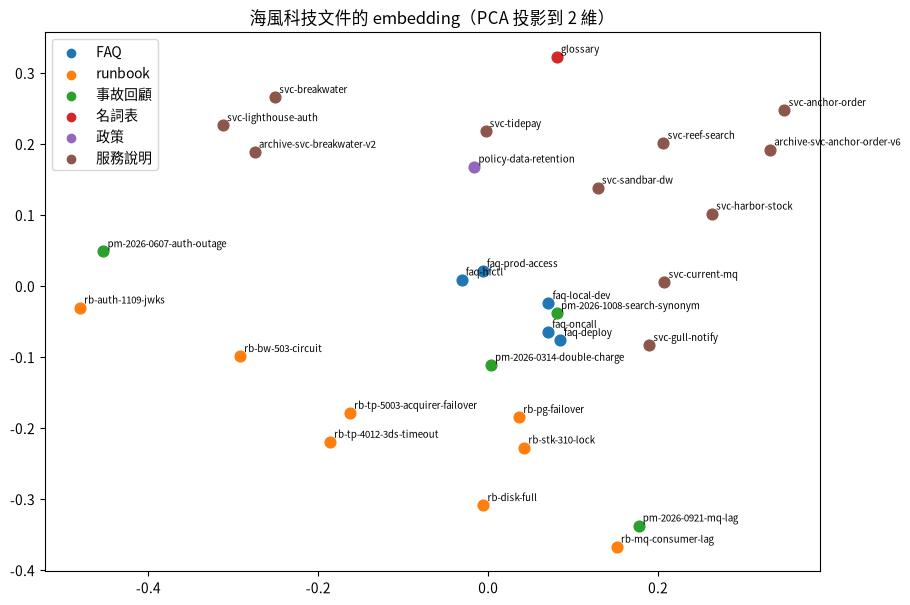

In [7]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

xy = PCA(n_components=2, random_state=0).fit_transform(doc_vecs)
types = sorted({d["type"] for d in docs})
colors = dict(zip(types, plt.cm.tab10.colors))

plt.figure(figsize=(10, 7))
for (x, y), d in zip(xy, docs):
    plt.scatter(x, y, color=colors[d["type"]], s=60)
    plt.annotate(d["id"], (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
for t in types:
    plt.scatter([], [], color=colors[t], label=t)
plt.legend()
plt.title("海風科技文件的 embedding（PCA 投影到 2 維）")
plt.show()

## Step 8：KMeans 分群

不給任何標籤，只看向量距離分成 5 群，然後印出每群有哪些文件。

In [8]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5, n_init=10, random_state=0).fit(doc_vecs)
clusters = {}
for d, c in zip(docs, kmeans.labels_):
    clusters.setdefault(int(c), []).append(d["id"])
for c, ids in sorted(clusters.items()):
    print(f"第 {c} 群：", ", ".join(ids))

第 0 群： pm-2026-0314-double-charge, pm-2026-0921-mq-lag, rb-tp-4012-3ds-timeout, rb-tp-5003-acquirer-failover, svc-tidepay
第 1 群： archive-svc-breakwater-v2, pm-2026-0607-auth-outage, rb-auth-1109-jwks, rb-bw-503-circuit, svc-breakwater, svc-lighthouse-auth
第 2 群： archive-svc-anchor-order-v6, svc-anchor-order, svc-gull-notify, svc-harbor-stock
第 3 群： faq-deploy, faq-hfctl, faq-local-dev, faq-oncall, faq-prod-access, policy-data-retention, rb-disk-full, rb-mq-consumer-lag, rb-pg-failover, rb-stk-310-lock
第 4 群： glossary, pm-2026-1008-search-synonym, svc-current-mq, svc-reef-search, svc-sandbar-dw


## Step 9：請 LLM 幫每一群取名字

分群只給編號。把每群的文件標題丟給 LLM，請它用幾個字概括，就得到「主題」。這是 cookbooks 601 的做法。

In [9]:
from course_utils.llm import chat

titles = {d["id"]: d["title"] for d in docs}
for c, ids in sorted(clusters.items()):
    listing = "\n".join(titles[i] for i in ids)
    name = chat([{"role": "user", "content": f"以下是一群文件的標題，用繁體中文、10 個字以內概括它們的共同主題，只回主題：\n{listing}"}])
    print(f"第 {c} 群（{len(ids)} 份）→ {' '.join(name.split())}")

第 0 群（5 份）→ 事故回顧 Runbook 支付說明
第 1 群（6 份）→ 安全與技術支援文件
第 2 群（4 份）→ 訂單、通知及庫存服務說明
第 3 群（10 份）→ IT運維與問題解決手冊
第 4 群（5 份）→ 資料與搜尋服務說明


## Step 10：把分群畫回散點圖

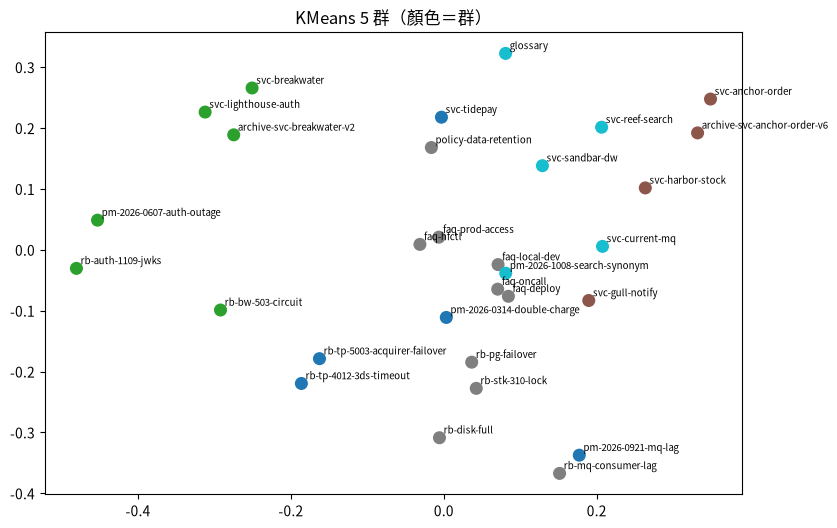

In [10]:
plt.figure(figsize=(9, 6))
plt.scatter(xy[:, 0], xy[:, 1], c=kmeans.labels_, cmap="tab10", s=70)
for (x, y), d in zip(xy, docs):
    plt.annotate(d["id"], (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.title("KMeans 5 群（顏色＝群）")
plt.show()

## Step 11：相似不等於相關

向量量的是「像不像」，不是「能不能回答問題」。下面三句裡，B 才回答了問題，但 A 的句型跟問題最像。

In [11]:
question = "TP-4021 可以重試嗎？"
candidates = {
    "A 句型很像、錯誤碼不同": "TP-4012 可以重試嗎？可以，使用者重新付款即可。",
    "B 真正的答案": "冪等鍵衝突是呼叫端程式錯誤，不可重試。",
    "C 無關": "breakwater 的限流是每分鐘 600 次。",
}
cv = np.array(embed([question, *candidates.values()]), dtype=np.float32)
cv /= np.linalg.norm(cv, axis=1, keepdims=True)
for name, score in zip(candidates, cv[1:] @ cv[0]):
    print(f"{score:.3f}  {name}")

0.766  A 句型很像、錯誤碼不同
0.518  B 真正的答案
0.438  C 無關


A 只差兩個數字，向量幾乎一樣；B 沒提到 `TP-4021` 這個代碼。錯誤碼、版本號、指令這類「字面上要一模一樣」的東西，是向量檢索的盲區。
Lab 3-05 會加上關鍵字檢索（BM25）補這個洞，Lab 3-06 用重排序模型直接判斷「能不能回答」。

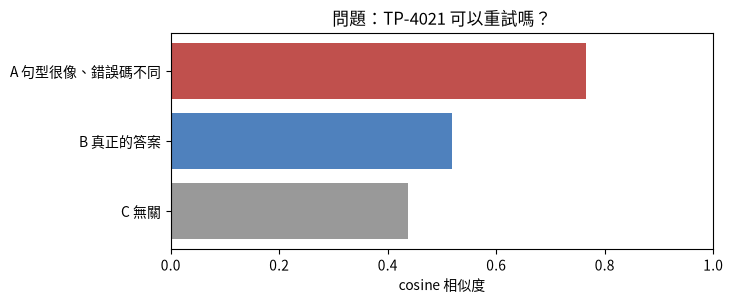

In [12]:
labels = list(candidates)
scores = cv[1:] @ cv[0]
plt.figure(figsize=(7, 2.8))
plt.barh(labels, scores, color=["#c0504d", "#4f81bd", "#999999"])
plt.xlim(0, 1)
plt.xlabel("cosine 相似度")
plt.title(f"問題：{question}")
plt.gca().invert_yaxis()
plt.show()

## 試試看

1. 在 Step 2 加一句英文「How do I handle a failed payment?」，看它跟中文問句的相似度。多語言模型的好處在這裡。
2. 把 KMeans 的群數改成 3 和 8，看分群結果和 LLM 取的名字怎麼變。
3. 自己寫三句話，試著讓「相似度最高的那句」不是正確答案。

## 小結

- embedding 把文字變成向量；先正規化，相似度就是一次矩陣乘法。
- 向量空間有結構：同一個服務、同一類文件會靠在一起，可以拿來搜尋、分群。
- 但相似不等於相關，錯誤碼這類細節向量分不清楚。下一本 Lab 3-02 先看沒有檢索時模型怎麼亂答，再用向量資料庫 Chroma 把資料塞給它。